# Questão 11 — Implementação de uma rede RBF

**Instituição:** Instituto Federal de Educação, Ciência e Tecnologia do Ceará — Campus Aracati  
**Curso:** Bacharelado em Ciência da Computação  
**Disciplina:** Inteligência Artificial  
**Professor:** Gabriel Duarte  
**Aluna:** Alane Damasceno Moreno  
**Atividade:** Lista de exercícios — Regressão Logística e RBF — Questão extra  
**Data:** 2 de outubro de 2026

## Objetivo geral

Implementar uma rede de base radial (RBF) em NumPy e comparar seu desempenho com o da Regressão Logística no problema de classificação do disco dentro do anel.

## Objetivos específicos

- Implementar o k-médias para encontrar os centros sem utilizar os rótulos.
- Calcular as respostas gaussianas e os pesos de saída por mínimos quadrados.
- Dividir os dados em 70% para treino e 30% para teste, padronizando as entradas com as estatísticas do treino.
- Avaliar os valores de $k\in\{5,10,20,40\}$ e as larguras $\sigma=d_{\max}/\sqrt{2k}$, $\sigma=0,3$ e $\sigma=0,8$.
- Apresentar a tabela de acurácias de teste e visualizar a fronteira de decisão.

## Procedimento

Neste trabalho, organizei o treinamento da RBF em duas fases: primeiro encontrei os centros usando apenas as entradas; depois calculei os pesos da saída pela pseudoinversa. Usei o NumPy na implementação da RBF e do k-médias. Utilizei o scikit-learn para gerar o conjunto de dados, separar treino e teste e executar a Regressão Logística de comparação.

Fixei a semente aleatória em 42 para permitir a reprodução do experimento. Adotei o limiar de 0,5 indicado na lista: a previsão é classe 1 quando a saída é maior ou igual a esse valor.

**Execução:** no Google Colab, basta executar as células em ordem ou selecionar **Ambiente de execução → Executar tudo**.

## 1. Bibliotecas e criação do conjunto de dados

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

SEMENTE = 42

# Gero os dados: o anel externo é a classe 0 e o disco interno é a classe 1.
X, y = make_circles(n_samples=200, factor=0.5, noise=0.08,
                    random_state=SEMENTE)

# Separo 70% para treino e 30% para teste, mantendo a proporção das classes.
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEMENTE
)

# Calculo média e desvio apenas no treino e aplico os mesmos valores ao teste.
media = X_treino.mean(axis=0)
desvio = X_treino.std(axis=0)
X_treino = (X_treino - media) / desvio
X_teste = (X_teste - media) / desvio

print(f"Treino: {len(X_treino)} amostras; teste: {len(X_teste)} amostras")

Treino: 140 amostras; teste: 60 amostras


## 2. Primeira fase: encontrar os centros

Implementei o k-médias usando somente as entradas de treino. Começo escolhendo $k$ pontos como centros iniciais. Em seguida, associo cada entrada ao centro mais próximo e atualizo cada centro pela média do grupo. Repito esse processo até os centros estabilizarem ou atingir o limite de iterações. Os rótulos não são usados nesta etapa.

In [10]:
def k_medias_numpy(X, k, semente=42, max_iter=200):
    # Encontro os centros com k-médias, sem consultar os rótulos.
    rng = np.random.default_rng(semente)
    centros = X[rng.choice(len(X), size=k, replace=False)].copy()

    for _ in range(max_iter):
        # Calculo a distância ao quadrado de cada entrada até cada centro.
        dist2 = np.sum((X[:, None, :] - centros[None, :, :]) ** 2, axis=2)
        grupo = np.argmin(dist2, axis=1)

        # Se um grupo ficar vazio, mantenho seu centro anterior.
        novos = np.array([
            X[grupo == j].mean(axis=0) if np.any(grupo == j) else centros[j]
            for j in range(k)
        ])
        if np.allclose(novos, centros):
            centros = novos
            break
        centros = novos

    return centros

## 3. Segunda fase: matriz dos sinos e pesos de saída

Para cada entrada $x_i$ e centro $c_j$, calculo a resposta gaussiana:

$$\phi_j(x_i)=\exp\left(-\frac{\lVert x_i-c_j\rVert^2}{\sigma^2}\right).$$

Organizo essas respostas na matriz $H$ e acrescento uma coluna de 1 para representar o viés. Com os centros e a largura fixados, encontro os pesos de saída usando $\beta=H^+y$, em que $H^+$ é a pseudoinversa. Assim, a segunda fase é resolvida diretamente por mínimos quadrados, sem épocas de atualização dos pesos de saída.

In [11]:
def matriz_rbf(X, centros, sigma):
    # Monto H com as respostas dos sinos e a coluna de viés.
    if sigma <= 0:
        raise ValueError("sigma precisa ser positivo")
    dist2 = np.sum((X[:, None, :] - centros[None, :, :]) ** 2, axis=2)
    sinos = np.exp(-dist2 / sigma**2)
    return np.column_stack((sinos, np.ones(len(X))))


def treinar_saida(X, y, centros, sigma):
    H = matriz_rbf(X, centros, sigma)
    return np.linalg.pinv(H) @ y


def prever_rbf(X, centros, sigma, beta):
    saida = matriz_rbf(X, centros, sigma) @ beta
    return (saida >= 0.5).astype(int)


def largura_heuristica(centros):
    # Uso a largura sugerida na lista: sigma = d_max / sqrt(2k).
    diferencas = centros[:, None, :] - centros[None, :, :]
    d_max = np.sqrt(np.sum(diferencas**2, axis=2)).max()
    return d_max / np.sqrt(2 * len(centros))

## 4. Avaliação dos hiperparâmetros

Avaliei $k\in\{5,10,20,40\}$. Para cada quantidade de centros, comparei a largura calculada por $d_{\max}/\sqrt{2k}$ com os valores fixos 0,3 e 0,8. Calculei a acurácia no conjunto de teste dividindo o número de previsões corretas pelo total de amostras.

A tabela registra as combinações pedidas na atividade. Para o gráfico, defini previamente a configuração $k=20$ com a largura heurística, sem selecionar uma configuração com base nos resultados do teste.

In [12]:
resultados = []
modelos = {}

for k in (5, 10, 20, 40):
    centros = k_medias_numpy(X_treino, k, semente=SEMENTE)
    sigma_h = largura_heuristica(centros)

    for nome_sigma, sigma in (("heurística", sigma_h), ("0,3", 0.3), ("0,8", 0.8)):
        beta = treinar_saida(X_treino, y_treino, centros, sigma)
        previstos = prever_rbf(X_teste, centros, sigma, beta)
        acuracia = np.mean(previstos == y_teste)

        resultados.append({
            "k": k, "tipo de σ": nome_sigma,
            "σ usado": sigma, "acurácia de teste": acuracia
        })
        modelos[(k, nome_sigma)] = (centros.copy(), sigma, beta.copy())

tabela = pd.DataFrame(resultados)
display(tabela.round({"σ usado": 4, "acurácia de teste": 4}))

,k,tipo de σ,σ usado,acurácia de teste
0,5,heurística,0.7803,0.8833
1,5,"0,3",0.3000,0.5500
2,5,"0,8",0.8000,0.8833
3,10,heurística,0.7986,1.0000
4,10,"0,3",0.3000,0.7833
5,10,"0,8",0.8000,1.0000
6,20,heurística,0.5684,1.0000
7,20,"0,3",0.3000,0.9667
8,20,"0,8",0.8000,1.0000
9,40,heurística,0.4272,1.0000


## 5. Comparação com Regressão Logística

In [13]:
rl = LogisticRegression().fit(X_treino, y_treino)
acuracia_rl = np.mean(rl.predict(X_teste) == y_teste)
print(f"Acurácia de teste da Regressão Logística: {acuracia_rl:.4f}")

# Uso k=20 e a largura heurística como exemplo definido para o gráfico.
centros_g, sigma_g, beta_g = modelos[(20, "heurística")]
acuracia_rbf = np.mean(prever_rbf(X_teste, centros_g, sigma_g, beta_g) == y_teste)
print(f"Acurácia de teste da RBF (k=20, σ={sigma_g:.4f}): {acuracia_rbf:.4f}")

Acurácia de teste da Regressão Logística: 0.4500
Acurácia de teste da RBF (k=20, σ=0.5684): 1.0000


## 6. Gráfico das fronteiras de decisão

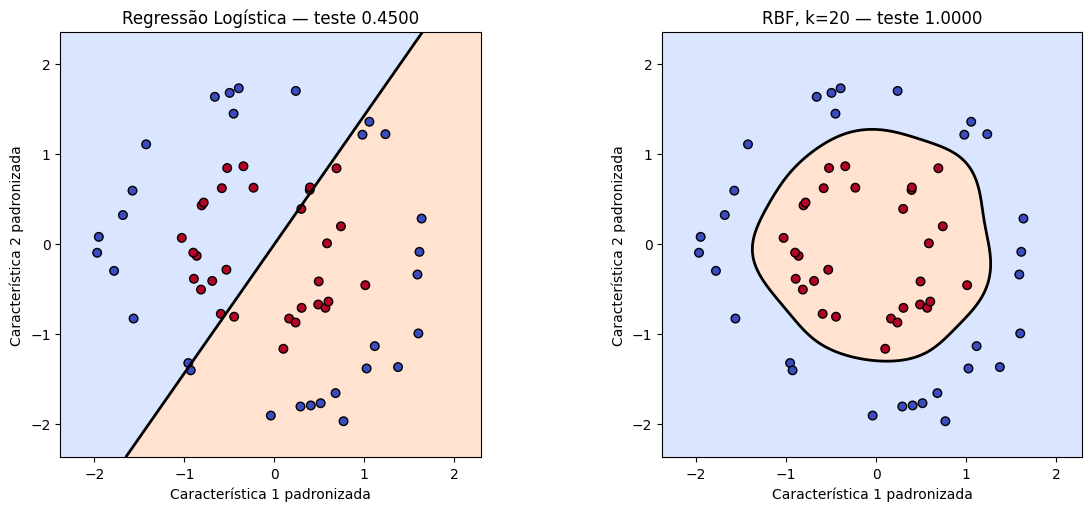

In [14]:
# Crio uma grade de pontos para visualizar as regiões previstas pelos modelos.
todos = np.vstack((X_treino, X_teste))
xx, yy = np.meshgrid(
    np.linspace(todos[:, 0].min() - 0.4, todos[:, 0].max() + 0.4, 300),
    np.linspace(todos[:, 1].min() - 0.4, todos[:, 1].max() + 0.4, 300),
)
grade = np.column_stack((xx.ravel(), yy.ravel()))

prob_rl = rl.predict_proba(grade)[:, 1].reshape(xx.shape)
saida_rbf = (matriz_rbf(grade, centros_g, sigma_g) @ beta_g).reshape(xx.shape)

fig, eixos = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
for eixo, valores, titulo in (
    (eixos[0], prob_rl, f"Regressão Logística — teste {acuracia_rl:.4f}"),
    (eixos[1], saida_rbf, f"RBF, k=20 — teste {acuracia_rbf:.4f}"),
):
    eixo.contourf(xx, yy, valores >= 0.5, levels=[-0.5, 0.5, 1.5],
                  colors=["#c7d9ff", "#ffd4b8"], alpha=0.65)
    eixo.contour(xx, yy, valores, levels=[0.5], colors="black", linewidths=2)
    eixo.scatter(X_teste[:, 0], X_teste[:, 1], c=y_teste,
                 cmap="coolwarm", edgecolors="black", s=38)
    eixo.set(title=titulo, xlabel="Característica 1 padronizada",
             ylabel="Característica 2 padronizada", aspect="equal")

plt.show()

## 7. Análise dos resultados e conclusão

Nesta execução, a Regressão Logística apresentou acurácia de teste de **0,4500**. A RBF com **20 centros** e largura heurística de aproximadamente **0,5684** apresentou acurácia de **1,0000**. Esses valores correspondem à divisão dos dados e à semente utilizadas neste notebook; não garantem o mesmo resultado em todo conjunto de dados.

Observei que a escolha dos hiperparâmetros alterou o desempenho. Com cinco centros e $\sigma=0,3$, a acurácia foi 0,5500, enquanto a largura heurística para os mesmos cinco centros resultou em 0,8833. Com dez centros, a largura heurística alcançou 1,0000, mas $\sigma=0,3$ ficou em 0,7833. Isso mostra que a quantidade de centros e a largura dos sinos precisam ser consideradas em conjunto.

### Resposta ao “Pare e pense”

A RBF ganha, com os centros, uma representação das entradas baseada em proximidades locais. Mesmo terminando em uma combinação linear, essa combinação usa respostas gaussianas que já são funções não lineares das entradas. Por isso, a rede consegue construir uma fronteira curva e separar o disco do anel, enquanto a Regressão Logística nas duas características originais produz uma reta.

O preço dessa flexibilidade é escolher, pelo menos, dois hiperparâmetros principais: o número de centros $k$ e a largura $\sigma$. Também é necessário definir como encontrar os centros. Neste trabalho, usei o k-médias e comparei as larguras indicadas na questão.

Concluo que a RBF foi mais adequada para este experimento porque representou a separação não linear entre as classes. A saída da RBF não é automaticamente uma probabilidade e pode ficar fora do intervalo $[0,1]$; utilizei essa saída com o limiar de classificação de 0,5.